In [ ]:
%matplotlib inline


# Numerical libraries
import numpy as np   

# Import Linear Regression machine learning library
from sklearn.linear_model import LinearRegression
from sklearn.linear_model import Ridge
from sklearn.linear_model import Lasso

from sklearn.metrics import r2_score

# to handle data in form of rows and columns 
import pandas as pd    

# importing ploting libraries
import matplotlib.pyplot as plt   

#importing seaborn for statistical plots
import seaborn as sns

In [ ]:
mpg_df = pd.read_csv("c:\dse\data\car-mpg.csv")  
mpg_df = mpg_df.drop('car_name', axis=1)
mpg_df['origin'] = mpg_df['origin'].replace({1: 'america', 2: 'europe', 3: 'asia'})
mpg_df = pd.get_dummies(mpg_df, columns=['origin'])

mpg_df = mpg_df.replace('?', np.nan)
mpg_df = mpg_df.apply(lambda x: x.fillna(x.median()),axis=0)  # 

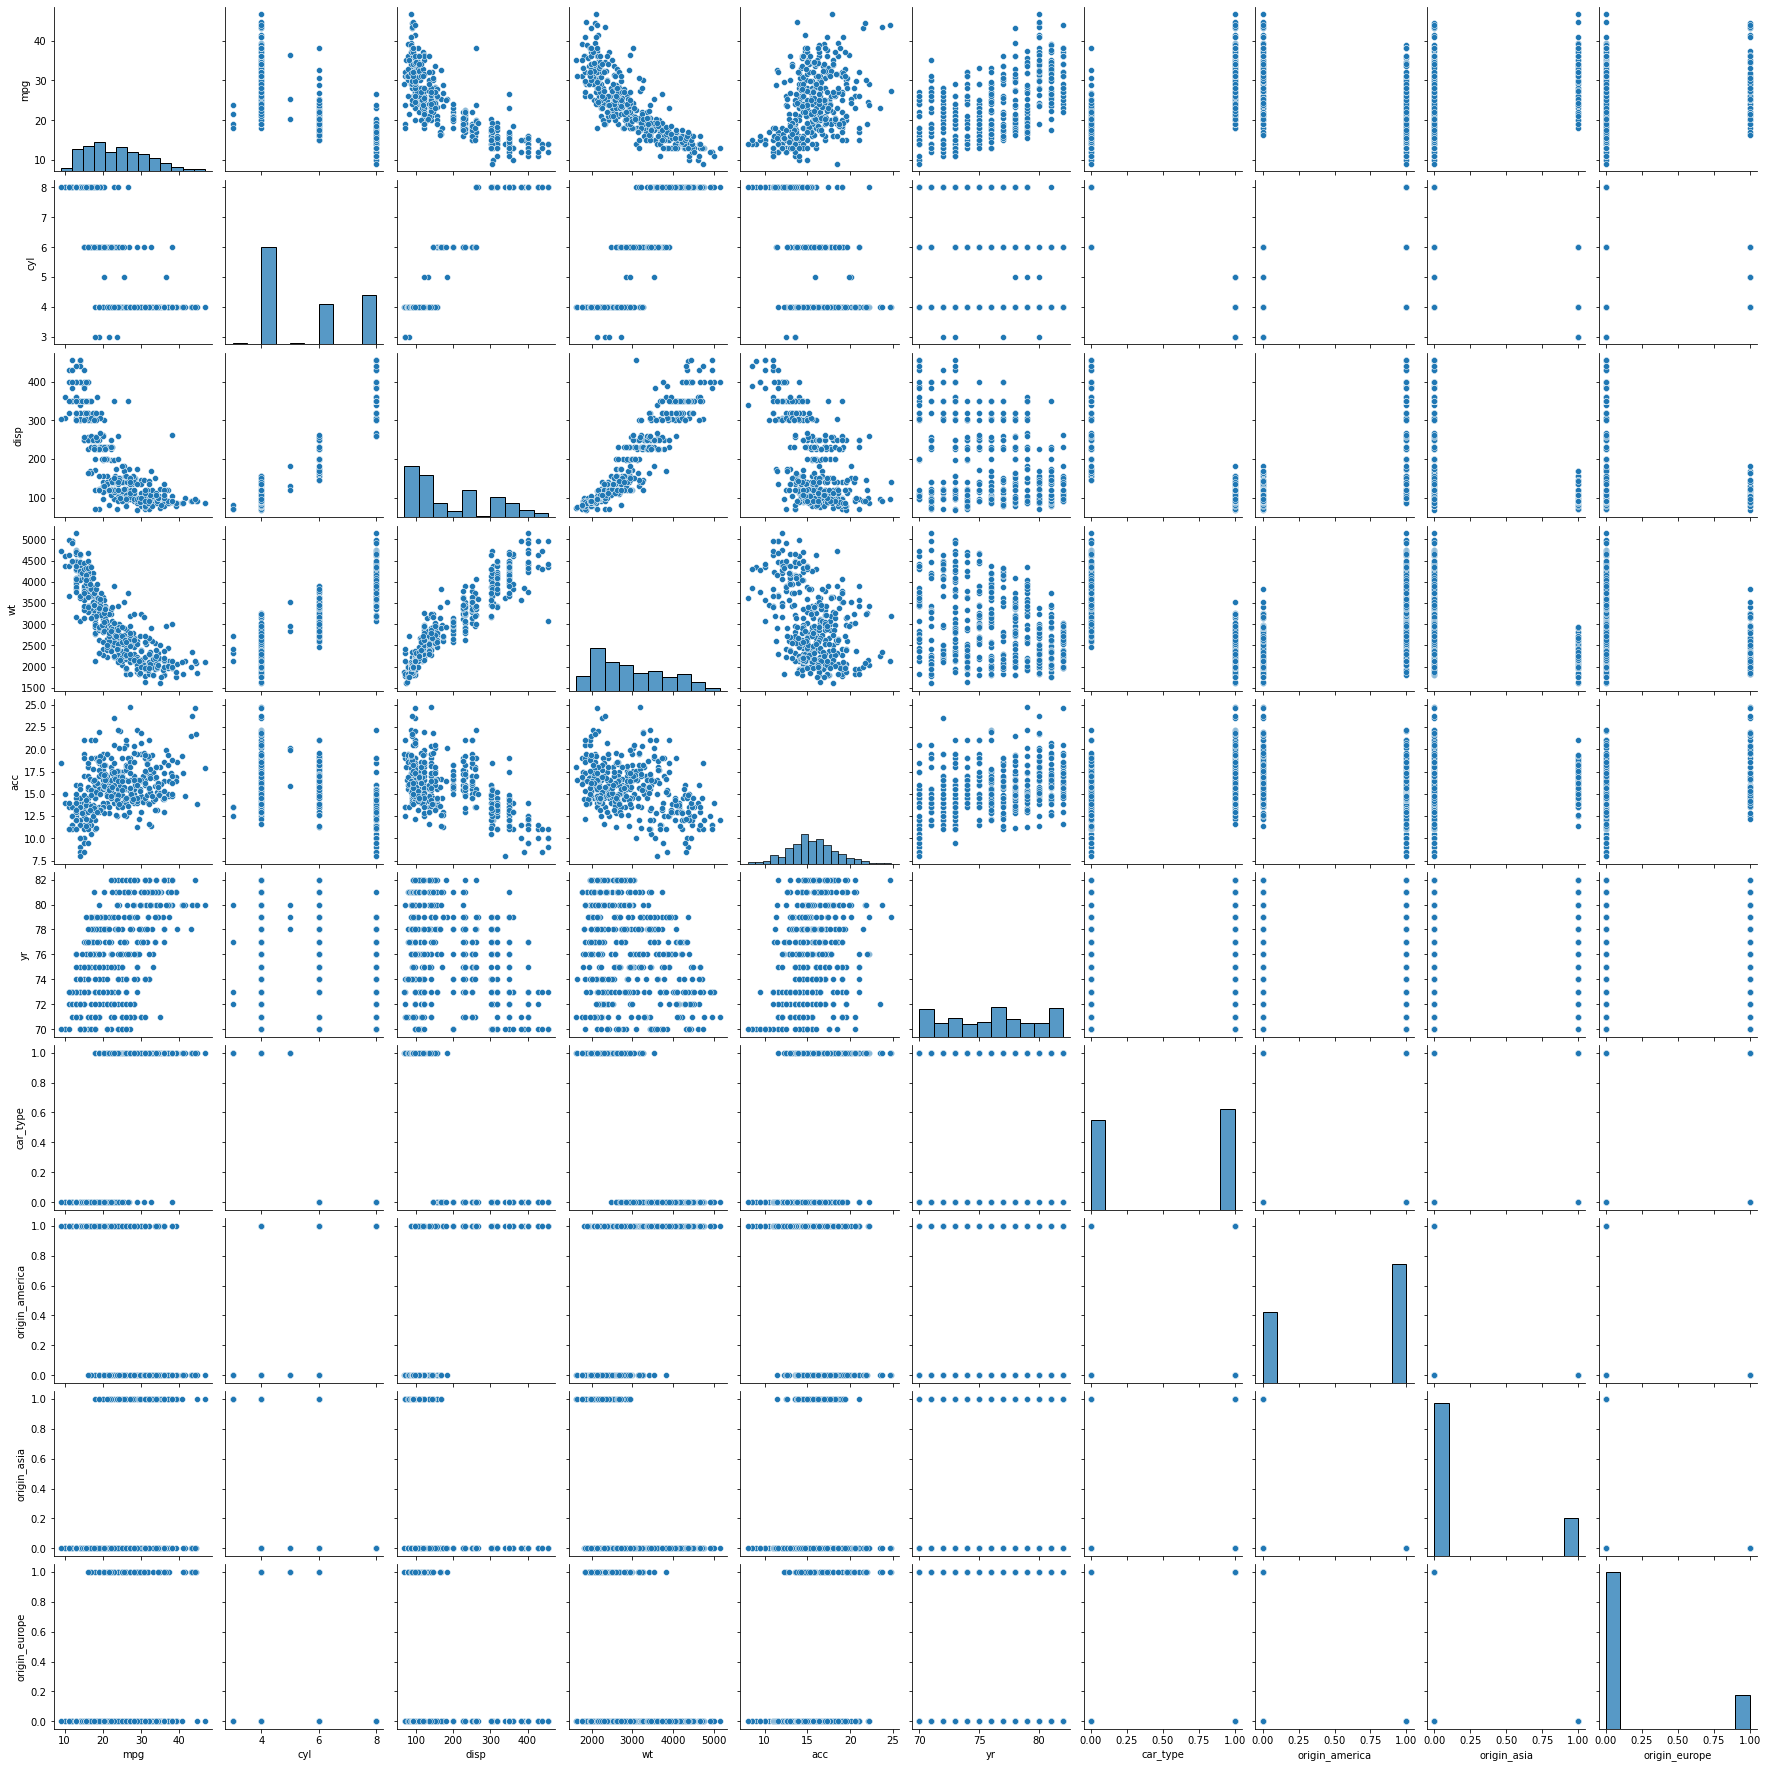

In [ ]:
sns.pairplot(mpg_df)

# separate independent and dependent variables

In [ ]:
# Copy all the predictor variables into X dataframe. Since 'mpg' is dependent variable drop it
X = mpg_df.drop('mpg', axis=1)

# Copy the 'mpg' column alone into the y dataframe. This is the dependent variable
y = mpg_df[['mpg']]


In [ ]:
from sklearn import preprocessing

# scale all the columns of the mpg_df. This will produce a numpy array
X_scaled = preprocessing.scale(X)
X_scaled = pd.DataFrame(X_scaled, columns=X.columns)  # ideally the training and test should be 

y_scaled = preprocessing.scale(y)
y_scaled = pd.DataFrame(y_scaled, columns=y.columns)  # ideally the training and test should be 

In [ ]:

from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(X_scaled, y_scaled, test_size=0.30, random_state=1)

# fit a simple linear model

In [ ]:
regression_model = LinearRegression()
regression_model.fit(X_train, y_train)

for idx, col_name in enumerate(X_train.columns):
    print("The coefficient for {} is {}".format(col_name, regression_model.coef_[0][idx]))

The coefficient for cyl is 0.3210223856916103
The coefficient for disp is 0.3248343091848394
The coefficient for hp is -0.22916950059437657
The coefficient for wt is -0.7112101905072294
The coefficient for acc is 0.01471368276419114
The coefficient for yr is 0.37558119495107434
The coefficient for car_type is 0.3814769484233101
The coefficient for origin_america is -0.07472247547584179
The coefficient for origin_asia is 0.044515252035678
The coefficient for origin_europe is 0.04834854953945406


In [ ]:
intercept = regression_model.intercept_[0]

print("The intercept for our model is {}".format(intercept))

The intercept for our model is 0.019284116103639722


# Create a regularized RIDGE model and note the coefficients

In [ ]:
ridge = Ridge(alpha=2)
ridge.fit(X_train,y_train)
print ("Ridge model:", (ridge.coef_))
    

Ridge model: [[ 0.28998676  0.25830994 -0.22600408 -0.6512147   0.00462896  0.36881053
   0.35490183 -0.07201299  0.04403238  0.0454102 ]]


# Create a regularized LASSO model and note the coefficients

In [ ]:
lasso = Lasso(alpha=0.02)
lasso.fit(X_train,y_train)
print ("Lasso model:", (lasso.coef_))

# Observe, many of the coefficients have become 0 indicating drop of those dimensions from the model

Lasso model: [ 0.          0.         -0.04660705 -0.51356005  0.          0.34283093
  0.13791821 -0.0741592   0.          0.        ]


## Let us compare their scores

In [ ]:
print(regression_model.score(X_train, y_train))
print(regression_model.score(X_test, y_test))


0.8343770256960538
0.8513421387780066


In [ ]:
print(ridge.score(X_train, y_train))
print(ridge.score(X_test, y_test))

0.8338232201579686
0.8542038399940475


In [ ]:
print(lasso.score(X_train, y_train))
print(lasso.score(X_test, y_test))

0.8119229420913319
0.8550399177953851


In [ ]:
# More or less similar results but with less complex models.  Complexity is a function of variables and coefficients
## Note - with Lasso, we get equally good result in test though not so in training.  Further, the number of dimensions is much less
# in LASSO model than ridge or un-regularized model

# Let us generate polynomial models reflecting the non-linear interaction between some dimensions

In [ ]:
from sklearn.preprocessing import PolynomialFeatures

In [ ]:
poly = PolynomialFeatures(degree = 2, include_bias=False)

#poly = PolynomialFeatures(2)

In [ ]:
X_poly = poly.fit_transform(X_scaled)
X_train, X_test, y_train, y_test = train_test_split(X_poly, y_scaled, test_size=0.30, random_state=1)
X_train.shape

(278, 65)

In [ ]:
#Formating of output can be done by getting columns using following command
poly.get_feature_names(X_scaled.columns)

['cyl',
 'disp',
 'hp',
 'wt',
 'acc',
 'yr',
 'car_type',
 'origin_america',
 'origin_asia',
 'origin_europe',
 'cyl^2',
 'cyl disp',
 'cyl hp',
 'cyl wt',
 'cyl acc',
 'cyl yr',
 'cyl car_type',
 'cyl origin_america',
 'cyl origin_asia',
 'cyl origin_europe',
 'disp^2',
 'disp hp',
 'disp wt',
 'disp acc',
 'disp yr',
 'disp car_type',
 'disp origin_america',
 'disp origin_asia',
 'disp origin_europe',
 'hp^2',
 'hp wt',
 'hp acc',
 'hp yr',
 'hp car_type',
 'hp origin_america',
 'hp origin_asia',
 'hp origin_europe',
 'wt^2',
 'wt acc',
 'wt yr',
 'wt car_type',
 'wt origin_america',
 'wt origin_asia',
 'wt origin_europe',
 'acc^2',
 'acc yr',
 'acc car_type',
 'acc origin_america',
 'acc origin_asia',
 'acc origin_europe',
 'yr^2',
 'yr car_type',
 'yr origin_america',
 'yr origin_asia',
 'yr origin_europe',
 'car_type^2',
 'car_type origin_america',
 'car_type origin_asia',
 'car_type origin_europe',
 'origin_america^2',
 'origin_america origin_asia',
 'origin_america origin_europ

# Fit a simple non regularized linear model on poly features-

In [ ]:
regression_model.fit(X_train, y_train)
print(regression_model.coef_[0])


[-4.25674751e+11 -6.71981812e-01 -3.52523804e-01 -2.59750366e-01
 -2.01766968e-01  3.94393921e-01 -5.34864801e+11 -9.61845707e+10
  7.17655284e+10  4.70815297e+10  5.33190377e+11 -4.37496185e-01
 -1.79504395e-01  5.51147461e-02  2.54364014e-01 -2.18967438e-01
 -5.37643620e+11 -8.13261622e+11  6.35699899e+11  3.67800150e+11
  2.52464294e-01  1.23138428e-02 -1.05484009e-01 -6.63452148e-02
  4.89879608e-01 -2.51029968e-01  3.44299316e-01 -5.40882111e-01
  1.39192581e-01 -5.83839417e-02  1.36795044e-01 -1.94458008e-01
 -1.47628784e-01 -1.79824829e-01 -1.13576889e-01  3.36914062e-02
  1.02729797e-01 -2.87246704e-02  5.44509888e-02 -3.57685089e-02
 -4.21195984e-01 -9.96932983e-02  1.98173523e-01 -7.01122284e-02
 -3.32183838e-02  5.85556030e-02  1.09153748e-01 -4.61883545e-02
 -3.77349854e-02  9.67712402e-02  1.37924194e-01  2.86941528e-02
 -8.18252563e-02  2.44426727e-02  7.53631592e-02  6.46239097e+10
 -4.77837377e+11  3.73509784e+11  2.16103471e+11  4.99358680e+10
 -4.49075645e+10 -1.64293

In [ ]:
print(regression_model.score(X_train, y_train))
print(regression_model.score(X_test, y_test))


0.9228025221316123
0.8486185739199313


In [ ]:
ridge = Ridge(alpha=0.05)
ridge.fit(X_train,y_train)
print ("Ridge model:", (ridge.coef_))

Ridge model: [[-0.07353659 -0.12575401 -0.1923963  -0.23610146 -0.00497448  0.25843522
   0.10158364 -0.02567918  0.02706906  0.00428351 -0.03991843 -0.01318724
  -0.00896763  0.01281712  0.04584355  0.00474853  0.01296079 -0.02674622
   0.03643343 -0.00417082  0.0031      0.0163749   0.02824011  0.01850793
   0.00862782 -0.02368017 -0.02152101  0.02283487  0.00343374 -0.01118939
   0.01826823 -0.01024885 -0.02587856 -0.0322075   0.01502947 -0.01018338
  -0.00843636  0.01789375 -0.02778354 -0.02399414 -0.04635672  0.00832848
   0.01415962 -0.02542155  0.01333903  0.03300725 -0.01618452 -0.06424329
   0.04110204  0.03860354  0.07930814  0.01217789 -0.02928872  0.01304742
   0.02356187 -0.01227363  0.00221122 -0.01131507  0.00904356  0.01333179
  -0.0222138   0.00632556  0.04092375 -0.0146367   0.00729346]]


In [ ]:
print(ridge.score(X_train, y_train))
print(ridge.score(X_test, y_test))


0.8628465416624708
0.8837347217269145


In [ ]:
lasso = Lasso(alpha=0.05)
lasso.fit(X_train,y_train)
print ("Lasso model:", (lasso.coef_))


Lasso model: [-0.         -0.         -0.12636998 -0.62005081  0.          0.34101129
  0.02994313 -0.01261526  0.          0.         -0.          0.
  0.          0.          0.         -0.          0.          0.
  0.         -0.          0.          0.          0.         -0.
 -0.         -0.          0.         -0.         -0.          0.
  0.         -0.         -0.05182359 -0.          0.         -0.
 -0.          0.10895045 -0.         -0.         -0.          0.
 -0.         -0.          0.          0.          0.         -0.064206
  0.          0.02403024  0.04613688  0.         -0.01441781  0.
  0.         -0.         -0.          0.          0.          0.
 -0.         -0.          0.         -0.          0.00783013]


In [ ]:
print(lasso.score(X_train, y_train))
print(lasso.score(X_test, y_test))


0.8733470832018457
0.8817111124837983


# Use Cross Validation to get a 95% confidence interval on the performance of the model

In [ ]:
from sklearn.model_selection import KFold
from sklearn.model_selection import cross_validate
from statistics import mean, stdev

In [ ]:
num_folds = 20
skf = KFold(n_splits=num_folds)

In [ ]:
def crossval(model, X_train, y_train, skf, flag):
    results = cross_validate(model, X_train, y_train, cv=skf, return_train_score= flag )
    for key in results:
        print(key , mean(results[key]) , stdev(results[key]) )
        print(''.format(key, mean(results[key])*100.0, stdev(results[key])*100.0))

In [ ]:
crossval(lasso, X_train, y_train, skf, True )

fit_time 0.002003967761993408 0.00057755931357957

score_time 0.0013558626174926757 0.0005762716005949966

test_score 0.846294672169471 0.05227524678440542

train_score 0.873685478626725 0.0026209810108185176



In [ ]:
crossval(ridge, X_train, y_train, skf, True )

fit_time 0.001949179172515869 0.000708877582952571

score_time 0.001287233829498291 0.0007415304091957486

test_score 0.8706122515532149 0.06139197368867866

train_score 0.911803488321314 0.0024387475471170437

